# Notebook 03: Statistical Uncertainty in Quantum Measurements

## Objective

This notebook studies statistical uncertainty in quantum measurement results.

We use Qiskit and Qiskit Aer to execute a QAOA-style Max-Cut circuit and
analyze the uncertainty of its measured objective value.

The notebook investigates:

1. Why quantum measurements contain statistical uncertainty.
2. How standard error changes with the number of shots.
3. How to calculate confidence intervals.
4. How often confidence intervals contain the ideal expectation.
5. How uncertainty affects runtime quality decisions.
6. How Hoeffding's inequality estimates a conservative shot requirement.

## Research motivation

A quantum runtime should not accept a result only because its measured
quality appears sufficient.

It should also consider whether the measurement evidence is reliable.

For example, a result with an estimated expected cut of 1.4 may not
provide enough evidence that its true expected cut exceeds a required
threshold of 1.2.

QFlowPilot should therefore consider both estimated quality and
statistical uncertainty.

## Important distinction

Qiskit Aer provides local quantum circuit simulation.

It does not reproduce real IBM Quantum queue times, hardware availability,
or actual cloud execution latency.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Define the Max-Cut experiment

We use a triangle graph containing three vertices and three edges.

Each edge has weight 1.

The objective is to maximize the total weight of edges whose endpoints
belong to different partitions.

For a binary assignment x:

C(x) = sum over edges (i,j) of:

       w(i,j) * (1 - (-1)^(x_i + x_j)) / 2

For this graph, the maximum possible cut value is 2.

We use a fixed QAOA circuit to generate measurement samples.

The purpose here is not to optimize QAOA parameters. It is to study
uncertainty in the measurements produced by a quantum circuit.

In [2]:
# Three-node weighted graph

edges = [
    (0, 1, 1),
    (1, 2, 1),
    (0, 2, 1)
]

num_qubits = 3

print("Number of vertices:", num_qubits)
print("Edges:", edges)

Number of vertices: 3
Edges: [(0, 1, 1), (1, 2, 1), (0, 2, 1)]


In [3]:
def calculate_cut_value(assignment):
    """
    Calculate the Max-Cut objective for a binary assignment.

    assignment[i] represents the partition of node i.
    """

    total_cut = 0

    for u, v, weight in edges:
        if assignment[u] != assignment[v]:
            total_cut += weight

    return total_cut


# Test assignments

test_assignments = [
    (0, 0, 0),
    (0, 0, 1),
    (0, 1, 0),
    (0, 1, 1),
    (1, 0, 0)
]

for assignment in test_assignments:
    print(
        f"Assignment {assignment}: "
        f"Cut value = {calculate_cut_value(assignment)}"
    )

Assignment (0, 0, 0): Cut value = 0
Assignment (0, 0, 1): Cut value = 2
Assignment (0, 1, 0): Cut value = 2
Assignment (0, 1, 1): Cut value = 2
Assignment (1, 0, 0): Cut value = 2


In [4]:
from itertools import product

all_assignments = list(product([0, 1], repeat=num_qubits))

assignment_results = []

for assignment in all_assignments:
    value = calculate_cut_value(assignment)

    assignment_results.append({
        "assignment": assignment,
        "cut_value": value
    })

exact_results = pd.DataFrame(assignment_results)

optimal_cut = exact_results["cut_value"].max()

optimal_assignments = exact_results[
    exact_results["cut_value"] == optimal_cut
]

print("Exact optimal cut value:", optimal_cut)
print("\nOptimal assignments:")
display(optimal_assignments)

Exact optimal cut value: 2

Optimal assignments:


,assignment,cut_value
1,"(0, 0, 1)",2
2,"(0, 1, 0)",2
3,"(0, 1, 1)",2
4,"(1, 0, 0)",2
5,"(1, 0, 1)",2
6,"(1, 1, 0)",2


## 2. Construct a QAOA circuit using Qiskit

We use a one-layer QAOA circuit (p = 1).

The cost Hamiltonian is:

H_C = sum over edges (i,j) of:

      w(i,j) * (I - Z_i Z_j) / 2

The mixer Hamiltonian is:

H_B = sum over vertices i of X_i

The circuit applies:

1. Hadamard gates to initialize a uniform superposition.
2. Cost-unitary operations using RZZ gates.
3. Mixer operations using RX gates.
4. Measurements in the computational basis.

We use fixed parameters:

gamma = 0.7
beta = 0.4

These parameters are chosen for this uncertainty experiment.
They are not claimed to be optimal.

QAOA circuit:


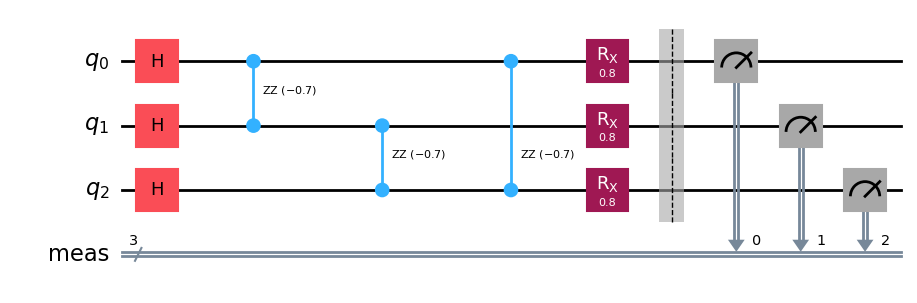

In [5]:
gamma = 0.7
beta = 0.4

def build_qaoa_circuit(measure=False):

    qc = QuantumCircuit(num_qubits)

    # Initial superposition
    for qubit in range(num_qubits):
        qc.h(qubit)

    # Cost unitary
    for u, v, weight in edges:
        qc.rzz(-gamma * weight, u, v)

    # Mixer unitary
    for qubit in range(num_qubits):
        qc.rx(2 * beta, qubit)

    if measure:
        qc.measure_all()

    return qc


state_circuit = build_qaoa_circuit(measure=False)
measurement_circuit = build_qaoa_circuit(measure=True)

print("QAOA circuit:")
display(measurement_circuit.draw("mpl"))

In [6]:
# Obtain the ideal quantum state using Qiskit Statevector

statevector = Statevector.from_instruction(state_circuit)

ideal_probabilities = statevector.probabilities_dict()

def decode_qiskit_bitstring(bitstring):
    """
    Qiskit displays measured bitstrings with the highest-index
    classical bit on the left.

    Reverse the bitstring to align its positions with graph nodes:
    node 0, node 1, node 2.
    """

    clean_bits = bitstring.replace(" ", "")

    return tuple(int(bit) for bit in clean_bits[::-1])


ideal_expected_cut = 0.0

for bitstring, probability in ideal_probabilities.items():

    assignment = decode_qiskit_bitstring(bitstring)

    cut_value = calculate_cut_value(assignment)

    ideal_expected_cut += probability * cut_value


print("Ideal expected cut:", ideal_expected_cut)
print("Exact optimal cut:", optimal_cut)

Ideal expected cut: 1.918421120407589
Exact optimal cut: 2


## 3. Execute the circuit with Qiskit Aer

A quantum circuit produces measurement outcomes according to a
probability distribution.

A finite number of shots provides only an estimate of that distribution.

For N shots, the estimated expected cut is:

C_hat = (1/N) * sum(C(x_i))

The sample variance is:

s^2 = sum((C(x_i) - C_hat)^2) / (N - 1)

The standard error is:

SE = s / sqrt(N)

As the number of shots increases, the standard error generally decreases.

We will compare several shot budgets:

100, 250, 500, 1000, 2000, and 5000.

In [7]:
simulator = AerSimulator()

compiled_circuit = transpile(
    measurement_circuit,
    simulator,
    optimization_level=1
)

print("Circuit transpiled for AerSimulator.")

Circuit transpiled for AerSimulator.


In [8]:
def counts_to_cut_samples(counts):
    """
    Convert Qiskit measurement counts into individual Max-Cut
    objective samples.
    """

    samples = []

    for bitstring, frequency in counts.items():

        assignment = decode_qiskit_bitstring(bitstring)

        cut_value = calculate_cut_value(assignment)

        samples.extend([cut_value] * frequency)

    return np.asarray(samples, dtype=float)


def calculate_statistics(samples, confidence=0.95):

    n = len(samples)

    mean_value = np.mean(samples)

    sample_variance = np.var(samples, ddof=1)

    standard_error = np.sqrt(sample_variance / n)

    degrees_of_freedom = n - 1

    t_critical = t.ppf(
        (1 + confidence) / 2,
        degrees_of_freedom
    )

    margin_of_error = t_critical * standard_error

    lower_bound = mean_value - margin_of_error
    upper_bound = mean_value + margin_of_error

    return {
        "shots": n,
        "mean": mean_value,
        "variance": sample_variance,
        "standard_error": standard_error,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "ci_width": upper_bound - lower_bound
    }

In [9]:
def run_experiment(shots, seed=42):

    job = simulator.run(
        compiled_circuit,
        shots=shots,
        seed_simulator=seed
    )

    result = job.result()

    counts = result.get_counts()

    samples = counts_to_cut_samples(counts)

    statistics = calculate_statistics(samples)

    return statistics, counts, samples


# Test with 1000 shots

statistics_1000, counts_1000, samples_1000 = run_experiment(
    shots=1000,
    seed=42
)

print("Measurement counts:")
print(counts_1000)

print("\nStatistical results:")
for key, value in statistics_1000.items():
    print(f"{key}: {value}")

Measurement counts:
{'010': 152, '001': 167, '100': 180, '101': 148, '011': 184, '110': 140, '000': 11, '111': 18}

Statistical results:
shots: 1000
mean: 1.942
variance: 0.11274874874874874
standard_error: 0.010618321371513896
lower_bound: 1.9211632277250388
upper_bound: 1.9628367722749611
ci_width: 0.04167354454992234


## 4. Understand the confidence interval

For a sufficiently large sample, we can estimate a 95% confidence
interval using:

CI = C_hat ± t_critical * SE

Where:

C_hat       = estimated expected cut
t_critical  = Student's t critical value
SE          = standard error

Interpretation:

A confidence interval describes the uncertainty of the estimated
expectation under the statistical assumptions of the interval.

It does not mean that 95% of individual measurement outcomes fall
inside the interval.

It also does not guarantee that the quantum algorithm found the
optimal solution.

We use the ideal statevector expectation as a reference to study
the behavior of these intervals.

In [10]:
shot_budgets = [100, 250, 500, 1000, 2000, 5000]

shot_results = []

for shots in shot_budgets:

    statistics, counts, samples = run_experiment(
        shots=shots,
        seed=100 + shots
    )

    shot_results.append(statistics)


shot_results_df = pd.DataFrame(shot_results)

display(shot_results_df)

,shots,mean,variance,standard_error,lower_bound,upper_bound,ci_width
0,100,1.940,0.117576,0.034289,1.871963,2.008037,0.136075
1,250,1.920,0.154217,0.024837,1.871083,1.968917,0.097834
2,500,1.936,0.124152,0.015758,1.905040,1.966960,0.061919
3,1000,1.920,0.153754,0.012400,1.895667,1.944333,0.048665
4,2000,1.921,0.151835,0.008713,1.903912,1.938088,0.034175
5,5000,1.918,0.157307,0.005609,1.907004,1.928996,0.021992


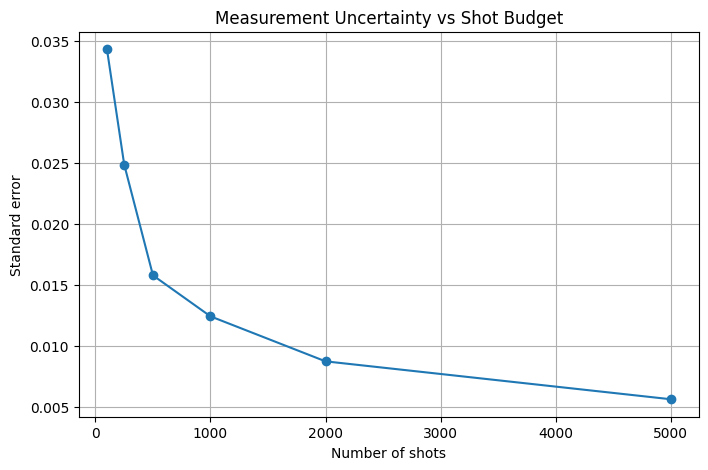

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    shot_results_df["shots"],
    shot_results_df["standard_error"],
    marker="o"
)

plt.xlabel("Number of shots")
plt.ylabel("Standard error")
plt.title("Measurement Uncertainty vs Shot Budget")

plt.grid(True)
plt.show()

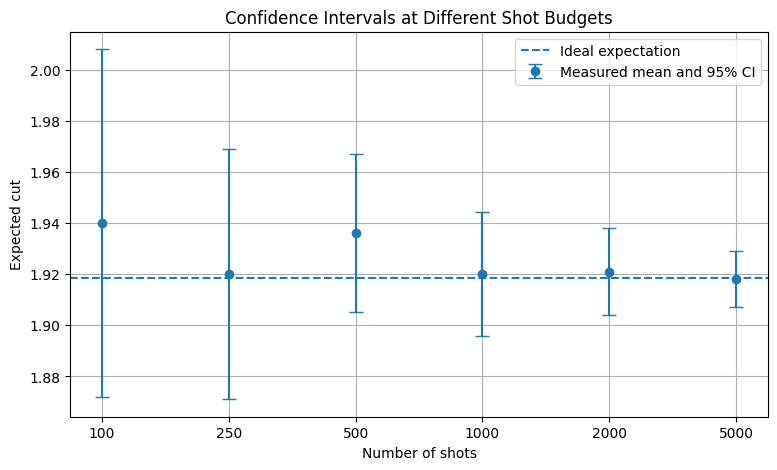

In [12]:
plt.figure(figsize=(9, 5))

x = np.arange(len(shot_results_df))

means = shot_results_df["mean"].values

lower_errors = (
    means - shot_results_df["lower_bound"].values
)

upper_errors = (
    shot_results_df["upper_bound"].values - means
)

plt.errorbar(
    x,
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=5,
    label="Measured mean and 95% CI"
)

plt.axhline(
    ideal_expected_cut,
    linestyle="--",
    label="Ideal expectation"
)

plt.xticks(
    x,
    shot_results_df["shots"]
)

plt.xlabel("Number of shots")
plt.ylabel("Expected cut")
plt.title("Confidence Intervals at Different Shot Budgets")

plt.legend()
plt.grid(True)
plt.show()

## 5. Evaluate confidence interval coverage

A single confidence interval cannot tell us whether our interval
estimation procedure performs reliably.

We therefore repeat the same experiment many times.

For each repetition:

1. Execute the same Qiskit circuit.
2. Collect measurement outcomes.
3. Calculate the estimated expected cut.
4. Calculate its 95% confidence interval.
5. Check whether the interval contains the ideal expectation.

Coverage is:

Coverage = Number of intervals containing the ideal expectation
            / Total number of experiments

For a well-calibrated 95% confidence interval procedure, the
coverage should be approximately 0.95 over many repetitions.

Because we use a finite number of repetitions, the observed
coverage will fluctuate.

In [13]:
repetitions = 40

coverage_results = []

for shots in shot_budgets:

    covered = 0
    interval_widths = []

    for repetition in range(repetitions):

        statistics, counts, samples = run_experiment(
            shots=shots,
            seed=10000 + shots * 100 + repetition
        )

        lower = statistics["lower_bound"]
        upper = statistics["upper_bound"]

        if lower <= ideal_expected_cut <= upper:
            covered += 1

        interval_widths.append(statistics["ci_width"])

    coverage_results.append({
        "shots": shots,
        "repetitions": repetitions,
        "coverage_count": covered,
        "coverage_rate": covered / repetitions,
        "average_ci_width": np.mean(interval_widths)
    })


coverage_df = pd.DataFrame(coverage_results)

display(coverage_df)

,shots,repetitions,coverage_count,coverage_rate,average_ci_width
0,100,40,35,0.875,0.150569
1,250,40,40,1.000,0.100620
2,500,40,38,0.950,0.068604
3,1000,40,37,0.925,0.048808
4,2000,40,40,1.000,0.034517
5,5000,40,38,0.950,0.022178


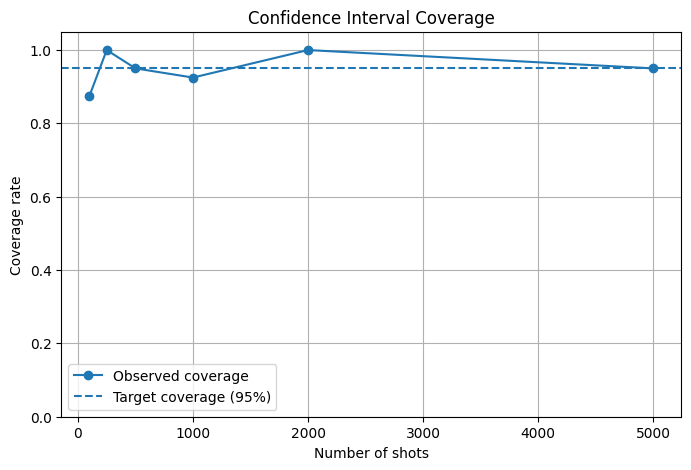

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    coverage_df["shots"],
    coverage_df["coverage_rate"],
    marker="o",
    label="Observed coverage"
)

plt.axhline(
    0.95,
    linestyle="--",
    label="Target coverage (95%)"
)

plt.ylim(0, 1.05)

plt.xlabel("Number of shots")
plt.ylabel("Coverage rate")
plt.title("Confidence Interval Coverage")

plt.legend()
plt.grid(True)
plt.show()

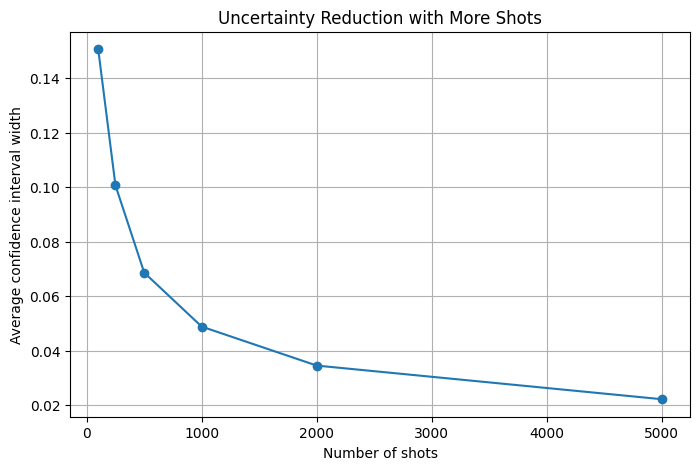

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    coverage_df["shots"],
    coverage_df["average_ci_width"],
    marker="o"
)

plt.xlabel("Number of shots")
plt.ylabel("Average confidence interval width")
plt.title("Uncertainty Reduction with More Shots")

plt.grid(True)
plt.show()

## 6. Estimate a conservative shot requirement

The Student's t confidence interval is useful for estimating
uncertainty from observed samples.

We can also use Hoeffding's inequality to obtain a conservative
shot requirement for a bounded observable.

If:

O_min <= O <= O_max

Then:

P(|O_hat - E[O]| >= epsilon)
    <= 2 * exp(-2 * N * epsilon^2 / (O_max - O_min)^2)

Rearranging:

N >= ((O_max - O_min)^2 / (2 * epsilon^2))
     * ln(2 / delta)

Where:

epsilon = maximum acceptable estimation error
delta   = failure probability

For our three-edge Max-Cut graph:

0 <= C(x) <= 3

Therefore, the observable range is 3.

This bound controls the error in estimating the expected cut.
It does not guarantee that the algorithm finds the optimal cut.

In [16]:
observable_min = 0
observable_max = 3

epsilon = 0.1
delta = 0.05

observable_range = observable_max - observable_min

required_shots = math.ceil(
    (
        observable_range ** 2
        / (2 * epsilon ** 2)
    )
    * math.log(2 / delta)
)

print("Observable range:", observable_range)
print("Maximum estimation error:", epsilon)
print("Failure probability:", delta)

print("\nConservative required shots:", required_shots)

Observable range: 3
Maximum estimation error: 0.1
Failure probability: 0.05

Conservative required shots: 1660


## 7. Use uncertainty in a runtime decision

Now we connect statistical uncertainty to QFlowPilot.

Assume the application requires:

Expected cut >= 1.2

A simple runtime policy can use the confidence interval:

PASS:
    Lower confidence bound >= quality threshold

FAIL:
    Upper confidence bound < quality threshold

UNCERTAIN:
    The confidence interval overlaps the threshold

This is more informative than comparing only the measured mean.

For example:

Measured mean = 1.35
Lower bound   = 1.10
Upper bound   = 1.60
Threshold     = 1.20

The measured mean is above the threshold, but the lower confidence
bound is below it.

The runtime should not confidently accept this result yet.

It may allocate more shots or perform another execution if the
remaining resource budget allows it.

This is a simplified decision rule. A production runtime would also
consider latency, cost, execution overhead, and the risks of repeated
statistical decisions.

In [17]:
quality_threshold = 1.2

def quality_decision(statistics, threshold):

    lower = statistics["lower_bound"]
    upper = statistics["upper_bound"]

    if lower >= threshold:
        return "PASS"

    elif upper < threshold:
        return "FAIL"

    else:
        return "UNCERTAIN"


decision_results = []

for _, row in shot_results_df.iterrows():

    statistics = row.to_dict()

    decision = quality_decision(
        statistics,
        quality_threshold
    )

    decision_results.append({
        "shots": int(row["shots"]),
        "estimated_quality": row["mean"],
        "lower_bound": row["lower_bound"],
        "upper_bound": row["upper_bound"],
        "quality_threshold": quality_threshold,
        "runtime_decision": decision
    })


decision_df = pd.DataFrame(decision_results)

display(decision_df)

,shots,estimated_quality,lower_bound,upper_bound,quality_threshold,runtime_decision
0,100,1.940,1.871963,2.008037,1.2,PASS
1,250,1.920,1.871083,1.968917,1.2,PASS
2,500,1.936,1.905040,1.966960,1.2,PASS
3,1000,1.920,1.895667,1.944333,1.2,PASS
4,2000,1.921,1.903912,1.938088,1.2,PASS
5,5000,1.918,1.907004,1.928996,1.2,PASS


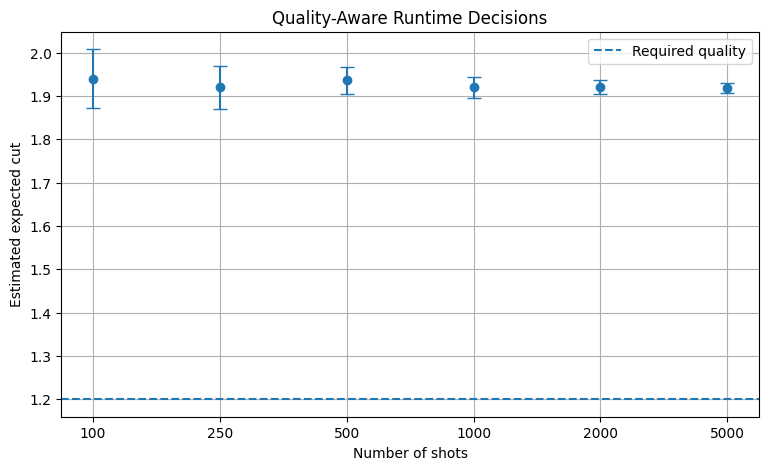

In [18]:
plt.figure(figsize=(9, 5))

x = np.arange(len(decision_df))

means = decision_df["estimated_quality"].values

lower_errors = (
    means - decision_df["lower_bound"].values
)

upper_errors = (
    decision_df["upper_bound"].values - means
)

plt.errorbar(
    x,
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=5
)

plt.axhline(
    quality_threshold,
    linestyle="--",
    label="Required quality"
)

plt.xticks(
    x,
    decision_df["shots"]
)

plt.xlabel("Number of shots")
plt.ylabel("Estimated expected cut")
plt.title("Quality-Aware Runtime Decisions")

plt.legend()
plt.grid(True)
plt.show()

## 8. Research interpretation

This experiment demonstrates several important observations.

### Observation 1: Measurement uncertainty

A finite number of shots produces an estimated expectation rather
than the exact expectation.

### Observation 2: Shot budget

Increasing the shot budget generally reduces standard error and
confidence interval width.

### Observation 3: Statistical confidence

Confidence intervals help the runtime distinguish between a
sufficiently supported result and an uncertain result.

### Observation 4: Quality-aware execution

A runtime should not make decisions using the measured mean alone.

It should also consider statistical uncertainty and the application's
required quality threshold.

### Observation 5: Resource trade-off

More shots can improve statistical precision, but additional
measurements require additional quantum execution resources.

The runtime must balance measurement confidence against execution
resources and latency.

### Limitations

1. This experiment uses ideal local Aer simulation.
2. It does not model real quantum hardware noise.
3. The confidence interval estimates the circuit's expected Max-Cut
   objective, not application-level quality.
4. The Hoeffding bound is conservative and may require many shots.
5. A production runtime must account for repeated testing, resource
   limits, and execution overhead.

In [19]:
shot_results_df.to_csv(
    "notebook03_shot_results.csv",
    index=False
)

coverage_df.to_csv(
    "notebook03_coverage_results.csv",
    index=False
)

decision_df.to_csv(
    "notebook03_quality_decisions.csv",
    index=False
)

print("Experimental results saved successfully.")

Experimental results saved successfully.


## 9. Completion checklist

- [ ] Executed a QAOA circuit using Qiskit.
- [ ] Generated measurements using Qiskit Aer.
- [ ] Calculated empirical expected cut values.
- [ ] Calculated sample variance and standard error.
- [ ] Constructed 95% confidence intervals.
- [ ] Compared different shot budgets.
- [ ] Evaluated confidence interval coverage.
- [ ] Calculated a Hoeffding shot requirement.
- [ ] Implemented a quality-aware runtime decision.
- [ ] Saved experimental results.

## Final research takeaway

Statistical uncertainty provides an important foundation for
quality-aware quantum runtime systems.

A runtime should consider not only the estimated quality of a
quantum result, but also the confidence it has in that estimate.

This provides a statistical basis for deciding whether to accept
a result, allocate additional shots, or consider another execution
strategy.